# Initial value problems with SymPy

An **initial value problem (IVP)** is a differential equation together with the value of the solution (and, for higher order, its derivatives) at one starting point $t_0$.

The generic forms of first-order and second-order ordinary differential equations (ODEs) with their initial conditions are:

- First-order IVP: one initial condition
$$ y'(t) = F\big(t, y(t)\big), \qquad y(t_0) = y_0. $$

- Second-order IVP: two initial conditions
$$ y''(t) = F\big(t, y(t), y'(t)\big), \qquad y(t_0) = y_0, \qquad y'(t_0) = y'_0. $$

In [38]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math

t = sp.symbols("t")
y = sp.Function("y")          # an unknown function y(t)

## Part A. A first-order IVP

### Step 1: write the equation

`y = sp.Function("y")` makes an **unknown function**. Then `y(t)` is the function, and `y(t).diff(t)` is $y'(t)$.

We write the equation with `sp.Eq(left side, right side)`.

**Use exact numbers.** Write $\tfrac12 y$ as `y(t)/2` or `sp.Rational(1, 2)*y(t)`, **not** `0.5*y(t)`. With floats, SymPy's answer gets decimals like `0.4000000` and is harder to read and to simplify.

In [39]:
ode = sp.Eq(y(t).diff(t) + y(t)/2, sp.sin(t))
ode

Eq(y(t)/2 + Derivative(y(t), t), sin(t))

### Step 2: the general solution

`sp.dsolve(ode)` returns **all** solutions of the equation. They contain a free constant `C1`: a differential equation alone does **not** fix the solution.

In [40]:
general = sp.dsolve(ode)
display(general)

print(sp.latex(general)) # in latex format

Eq(y(t), C1*exp(-t/2) + 2*sin(t)/5 - 4*cos(t)/5)

y{\left(t \right)} = C_{1} e^{- \frac{t}{2}} + \frac{2 \sin{\left(t \right)}}{5} - \frac{4 \cos{\left(t \right)}}{5}


The answer is an equation `Eq(y(t), ...)`. Its right side is `general.rhs`.

- $C_1 e^{-t/2}$: the **transient**. It solves $y' + \tfrac12 y = 0$ and dies out.
- $\tfrac25\sin t - \tfrac45\cos t$: the **steady state**. It is forced by $\sin t$ and stays.


### Step 3: Solving IVP using `ics=`

The initial condition $y(0) = 1$ picks **one** curve from the family. To find this solution, pass the initial condition as a dictionary `ics={y(0): 1}` (*ics* = *initial conditions*).

In [41]:
sol = sp.dsolve(ode, ics={y(0): 1})
sol

Eq(y(t), 2*sin(t)/5 - 4*cos(t)/5 + 9*exp(-t/2)/5)

### Step 5: check the answer

**Always check.** Two things must hold:
1. **the equation:** put $y(t)$ into $y' + \tfrac12 y - \sin t$. It must simplify to $0$;
2. **the initial condition:** $y(0)$ must be $1$.

`sp.checkodesol(ode, sol)` does check 1 for us and returns `(True, 0)` if the solution is correct.

In [42]:
Y = sol.rhs
print("initial:   y(0) =", Y.subs(t, 0))
print("checkodesol:", sp.checkodesol(ode, sol))

initial:   y(0) = 1
checkodesol: (True, 0)


### Step 6: plot the solution

To plot, we turn the SymPy formula into a NumPy function with `sp.lambdify`.

We also plot the solutions for several other initial values $y(0) = y_0$. Same equation, different starting points.

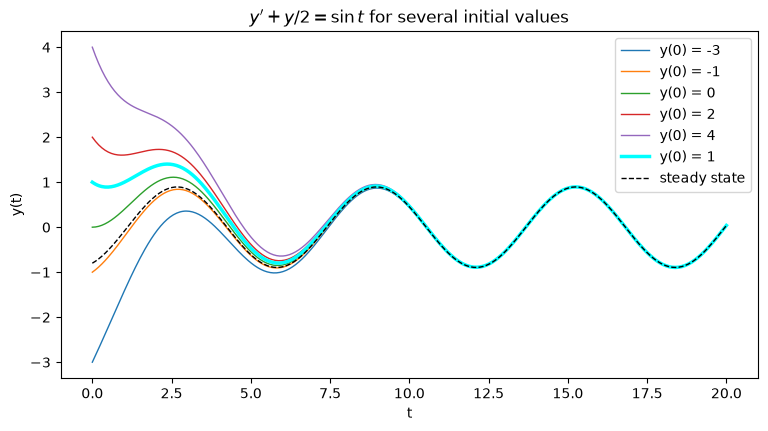

In [55]:
Y_num = sp.lambdify(t, Y, "numpy")
tt = np.linspace(0, 20, 400)

fig, ax = plt.subplots(figsize=(9, 4.5))
for y0 in [-3, -1, 0, 2, 4]:
    sol = sp.dsolve(ode, ics={y(0): y0})
    Y0 = sol.rhs
    ax.plot(tt, sp.lambdify(t, Y0, "numpy")(tt), lw=1, label=f"y(0) = {y0}")
ax.plot(tt, Y_num(tt), color="cyan", lw=2.5, label="y(0) = 1")
steady = sp.Rational(2, 5)*sp.sin(t) - sp.Rational(4, 5)*sp.cos(t)
steady_np = sp.lambdify(t, steady, "numpy")
ax.plot(tt, steady_np(tt), "k--", lw=1, label="steady state")
ax.set_xlabel("t"); ax.set_ylabel("y(t)")
ax.set_title(r"$y' + y/2 = \sin t$ for several initial values")
ax.legend(loc="upper right")
plt.show()

- Every initial value gives a **different** solution: this is why the IVP needs $y(0)$.
- After $t \approx 10$ all curves lie on the **same** steady state. The transient $C_1 e^{-t/2}$ has died out: $e^{-5} \approx 0.007$.

## Part B. A second-order IVP

A mass on a spring, with friction:
$$ y'' + 2y' + 5y = 0, \qquad y(0) = 1, \quad y'(0) = 0. $$
($y$ = position; the mass starts at $y = 1$, at rest.)

A **second-order** equation has **two** free constants $C_1, C_2$, so we need **two** initial conditions: the position $y(0)$ and the velocity $y'(0)$.

### Step 1: the general solution

In [44]:
ode2 = sp.Eq(y(t).diff(t, 2) + 2*y(t).diff(t) + 5*y(t), 0)
sp.dsolve(ode2)

Eq(y(t), (C1*sin(2*t) + C2*cos(2*t))*exp(-t))

### Step 2: one condition is not enough

With only $y(0) = 1$, one constant is still free (SymPy calls it `C1`):

In [45]:
sp.dsolve(ode2, ics={y(0): 1})

Eq(y(t), (C1*sin(2*t) + cos(2*t))*exp(-t))

### Step 3: both conditions

The condition on the **derivative** is written as: take $y'(t)$, then put $t = 0$:
```python
y(t).diff(t).subs(t, 0)        # this is y'(0)
```

In [46]:
sol2 = sp.dsolve(ode2, ics={y(0): 1, y(t).diff(t).subs(t, 0): 0})
sol2

Eq(y(t), (sin(2*t)/2 + cos(2*t))*exp(-t))

In [47]:
Y2 = sol2.rhs
print("checkodesol:", sp.checkodesol(ode2, sol2))
print("y(0)  =", Y2.subs(t, 0))
print("y'(0) =", Y2.diff(t).subs(t, 0))

checkodesol: (True, 0)
y(0)  = 1
y'(0) = 0


### Step 4: plot position and velocity

`Y2.diff(t)` is the velocity. It is a SymPy expression too, so we lambdify it the same way.

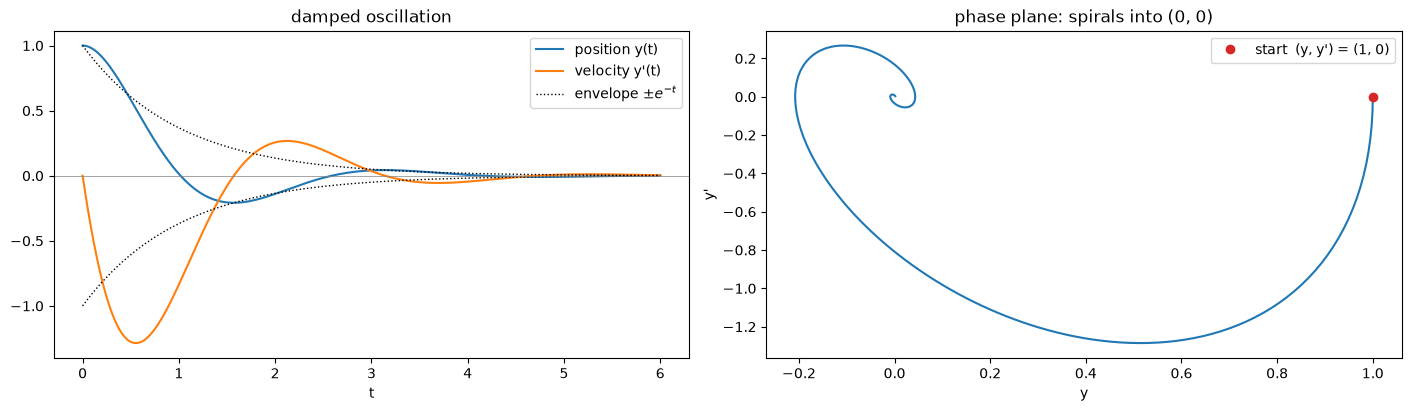

In [48]:
pos = sp.lambdify(t, Y2, "numpy")
vel = sp.lambdify(t, Y2.diff(t), "numpy")
tt = np.linspace(0, 6, 400)

fig, axs = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
axs[0].plot(tt, pos(tt), label="position y(t)")
axs[0].plot(tt, vel(tt), label="velocity y'(t)")
axs[0].plot(tt,  np.exp(-tt), "k:", lw=1, label=r"envelope $\pm e^{-t}$")
axs[0].plot(tt, -np.exp(-tt), "k:", lw=1)
axs[0].axhline(0, color="gray", lw=0.5)
axs[0].set_xlabel("t"); axs[0].legend(); axs[0].set_title("damped oscillation")

axs[1].plot(pos(tt), vel(tt))
axs[1].plot(1, 0, "o", color="tab:red", label="start  (y, y') = (1, 0)")
axs[1].set_xlabel("y"); axs[1].set_ylabel("y'"); axs[1].legend()
axs[1].set_title("phase plane: spirals into (0, 0)")
plt.show()

## Part C. When `dsolve` cannot find a formula

Most differential equations have **no formula** for the solution. For example
$$ y' = t + \sin y, \qquad y(0) = 0. $$

`dsolve` then raises an error. We catch it with `try` / `except`, so the notebook keeps running.

In [49]:
ode3 = sp.Eq(y(t).diff(t), t + sp.sin(y(t)))
try:
    sol3 = sp.dsolve(ode3, ics={y(0): 0})
except Exception as e:                 # dsolve raises an error when it fails
    print("SymPy gives up:", e)

SymPy gives up: The given ODE -t - sin(y(t)) + Derivative(y(t), t) cannot be solved by the lie group method


## Summary

| | first order | second order |
|---|---|---|
| equation | `sp.Eq(y(t).diff(t) + ..., ...)` | `sp.Eq(y(t).diff(t, 2) + ..., ...)` |
| free constants | $C_1$ | $C_1, C_2$ |
| initial conditions | `ics={y(0): y0}` | `ics={y(0): y0, y(t).diff(t).subs(t, 0): v0}` |
| check | `sp.checkodesol(ode, sol)`, and $y(0)$ | `sp.checkodesol(ode, sol)`, and $y(0)$, $y'(0)$ |

- **Always check** the equation and the initial condition(s).
- **Use exact numbers** (`sp.Rational`, `y(t)/2`), not floats.
- **Not every equation has a formula**: `dsolve` can fail.

## Exercises

**Syntax**

| task | call |
|---|---|
| unknown function | `y = sp.Function("y")`, then `y(t)`, `y(t).diff(t)`, `y(t).diff(t, 2)` |
| equation | `sp.Eq(left, right)` |
| solve the IVP | `sp.dsolve(ode, ics={y(0): a})`, or `ics={y(0): a, y(t).diff(t).subs(t, 0): b}` |
| check | `sp.checkodesol(ode, sol)`; `sp.limit(expr, t, sp.oo)` |
| exact fraction | `sp.Rational(1, 10)` for $\tfrac{1}{10}$ (not `0.1`) |
| numbers | `Y_num = sp.lambdify(t, sol.rhs, "numpy")` |
| plot a function | `tt = np.linspace(0, 10, 400)`<br>`fig, ax = plt.subplots(figsize=(9, 4.5))`<br>`ax.plot(tt, Y_num(tt), label="y(t)")`<br>`ax.set_xlabel("t"); ax.legend()`<br>`plt.show()` |

**Exercise 1.** Solve the IVP
$$ y' = y\,(1 - y), \qquad y(0) = \tfrac{1}{10}. $$

(a) Solve the IVP with `dsolve`. Check your answer with `checkodesol`, and check $y(0)$.

(b) Find $\lim_{t\to\infty} y(t)$ with `sp.limit`. Plot the solutions for $y(0) = 0.1,\ 0.5,\ 1.5$ on $[0, 10]$. What do they all approach?

In [50]:
# Exercise 1

**Exercise 2.** Solve the second-order IVP
$$ y'' - y = t, \qquad y(0) = 1, \quad y'(0) = 0. $$

(a) Solve the IVP with `dsolve` and `ics=` (two initial conditions). Check your answer with `checkodesol`, and check $y(0)$ and $y'(0)$.

(b) Plot $y(t)$ and $y'(t)$ on $[0, 2]$.

In [51]:
# Exercise 2